# GNK shipping-equity research

This executed notebook reads the reviewed company package and calculates independently of
the Excel workbook. It compares broker-anchored asset backing, finite-life cash flow and
the freight-rate assumptions implied by the dated share price. Results are scenarios, not
price targets or recommendations.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from shipping_equity.data import load_company
from shipping_equity.valuation import value_company, reverse_valuation
from shipping_equity.reconcile import reconcile

ROOT = Path.cwd()
company = load_company(ROOT / 'data/companies/GNK')
OUT = ROOT / f"outputs/{company.metadata['ticker'].lower()}-{company.metadata['valuation_date']}"
print(company.metadata['name'], company.metadata['valuation_date'])
print('Evidence status:', company.metadata['evidence_status'])
print('Input SHA-256:', company.fingerprint)

Genco Shipping & Trading 2026-10-12
Evidence status: Conditional valuation: aggregate broker fleet mark is allocated by carrying value; post-quarter cash is estimated
Input SHA-256: f06f117695c938ef661b14fb99bc958b9191c315077db08370e0173376704563


## Evidence and fleet

The source register distinguishes observed facts from estimates. Vessel values may use an
aggregate market anchor allocated across ships for runoff mechanics; read the audit notes
before interpreting vessel-level numbers.

In [2]:
display(pd.DataFrame(company.sources)[['id','published','title','url']])
display(company.fleet.groupby('vessel_class').agg(
    vessels=('vessel_id','count'), dwt=('dwt','sum'), fleet_value=('appraisal_usd','sum')))
display(pd.Series(company.metadata.get('audit_notes', []), name='Audit notes'))

,id,published,title,url
0,GNK_Q2_10Q,2026-08-05,Genco Q2 2026 Form 10-Q,https://www.sec.gov/Archives/edgar/data/132620...
1,GNK_Q2_RELEASE,2026-08-05,Genco Q2 2026 earnings release,https://investors.gencoshipping.com/news/press...
2,GNK_VOLUNTEER,2026-08-12,Genco Volunteer delivery announcement,https://investors.gencoshipping.com/news/press...
3,GNK_FLEET,2026-08-12,Genco current fleet register,https://www.gencoshipping.com/fleet/
4,GNK_PRICE,2026-10-12,GNK historical close,https://chartexchange.com/symbol/nyse-gnk/hist...


,vessels,dwt,fleet_value
vessel_class,,,
Capesize,18,3234682,819244224
Newcastlemax,2,416000,196047639
Supramax,9,522830,94539376
Ultramax,15,942206,378685428


0    August 12 company release says 43 vessels and ...
1    Aggregate broker value is reverse-engineered a...
Name: Audit notes, dtype: object

## Scenario outputs

Asset NAV and DCF answer different questions. NAV applies the selected mark to the fleet
and bridges cash, debt and claims. DCF models operating cash through each ship's retirement,
with no perpetual terminal value or unfinanced replacement fleet.

,price,nav_per_share,dcf_per_share,price_nav,next_year_ufcf,minimum_cash_headroom
bear,26.67,20.99,-2.16,1.27,3.041358e+07,-2.795984e+08
base,26.67,27.15,19.23,0.98,1.427186e+08,5.499503e+07
bull,26.67,31.95,47.88,0.83,2.530723e+08,1.060860e+08


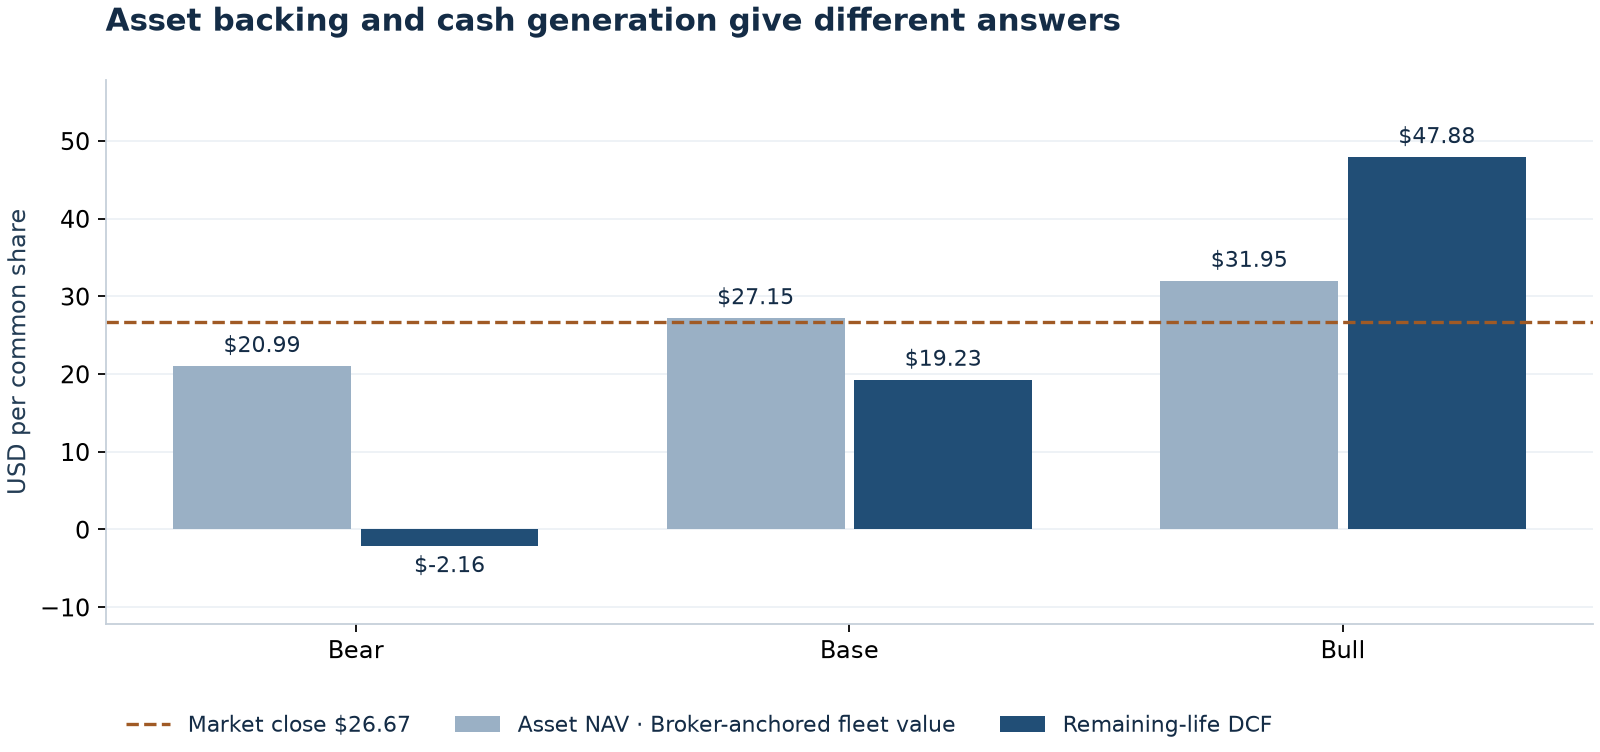

In [3]:
cases = {name: value_company(company, name) for name in ['bear','base','bull']}
summary = pd.DataFrame({name: result.summary for name, result in cases.items()}).T
display(summary[['price','nav_per_share','dcf_per_share','price_nav','next_year_ufcf','minimum_cash_headroom']].round(2))
display(Image(filename=str(OUT / 'valuation.png')))

## Assumptions and reverse valuation

The reverse valuation changes one common multiplier across open class rates and reprices
the full model, including working capital. It does not estimate a probability distribution.

In [4]:
assumptions = pd.DataFrame(company.assumptions.values())
display(assumptions[['label','unit','bear','base','bull','rationale']])
root = reverse_valuation(company)
display(root)
if root['status'] == 'solved':
    repriced = value_company(company, rate_multiplier=root['multiplier'])
    assert abs(repriced.summary['dcf_per_share'] - company.facts['share_price']) < 1e-8

,label,unit,bear,base,bull,rationale
0,Newcastlemax open TCE,USD/day,18000.00,2.600000e+04,3.400000e+04,Illustrative class-rate range. No licensed cla...
1,Capesize open TCE,USD/day,16000.00,2.400000e+04,3.200000e+04,Illustrative class-rate range. No licensed cla...
2,Ultramax open TCE,USD/day,11500.00,1.650000e+04,2.100000e+04,Illustrative class-rate range. No licensed cla...
3,Supramax open TCE,USD/day,10500.00,1.450000e+04,1.900000e+04,Illustrative class-rate range. No licensed cla...
4,Discount rate,fraction,0.12,1.000000e-01,8.500000e-02,Nominal unlevered discount-rate scenarios; not...
5,Appraisal multiplier,multiple,0.85,1.000000e+00,1.120000e+00,Scenario multiplier on the broker-anchored agg...
6,Retirement age,years,23.00,2.500000e+01,2.700000e+01,Retire July 1 of build year plus age; build mo...
7,Unavailable share of owned days,fraction,0.05,3.500000e-02,2.500000e-02,H1 owned-fleet availability implies about 3.9%...
8,Vessel operating cost,USD/day,7300.00,6.800000e+03,6.400000e+03,"H1 disclosed DVOE was $6,781/day; Q3 budget wa..."
9,Management cost,USD/day,300.00,2.350000e+02,2.000000e+02,H1 technical management expense divided by own...


{'status': 'solved',
 'multiplier': 1.1608882897999138,
 'residual': 1.2838050622576702e-09,
 'iterations': 32,
 'bounds': [0, 3]}

## Cash flow, financing and reconciliation

Financing is kept separate from unlevered enterprise value. Excel and Python use independent
implementations; reconciliation establishes arithmetic agreement, not assumption accuracy.

,label,owned,available,revenue,operating,maintenance,newbuild,scrap,delta_wc,ufcf,pv
0,Q4:26 stub,3520.0,3396.80,68193756.13,32305210.25,966504.91,0.0,0.0,4931380.86,26066355.70,25527480.20
1,Q1:27,3960.0,3821.40,77072583.04,36511348.56,1092343.85,0.0,0.0,100669.10,34932972.70,33416176.76
2,Q2:27,4004.0,3863.86,78312514.46,37098737.31,1109917.30,0.0,0.0,107694.48,35489562.96,33151413.17
3,Q3:27,4048.0,3906.32,79567101.38,37693068.77,1127698.47,0.0,0.0,109423.38,36058111.41,32882978.35
4,Q4:27,4048.0,3906.32,79965241.20,37881678.27,1133341.27,0.0,0.0,110570.35,36237940.44,32262532.30
5,Q1:28,4004.0,3863.86,79489680.25,37656392.30,1126601.18,0.0,0.0,110518.20,36021824.52,31317048.99
6,Q2:28,4004.0,3863.86,79883098.60,37842765.12,1132177.07,0.0,0.0,110459.77,36200712.79,30733528.70
7,Q3:28,4048.0,3906.32,81162846.68,38449016.09,1150314.84,0.0,0.0,111617.91,36781269.11,30485181.89
8,Q4:28,4048.0,3906.32,81568971.33,38641408.22,1156070.82,0.0,0.0,112787.88,36964704.67,29909978.20
9,Q1:29,3960.0,3821.40,80190665.92,37988468.00,1136536.20,0.0,0.0,112117.12,36338861.36,28720616.32


,opening_debt,repayment,closing_debt,interest,ufcf,equity_cash,opening_cash,closing_cash,mincash,headroom
0,380000000.0,0.0,380000000.0,4789041.10,26066355.70,21277314.60,6.371772e+07,8.499503e+07,30000000.0,5.499503e+07
1,380000000.0,0.0,380000000.0,5387671.23,34932972.70,29545301.47,8.499503e+07,1.145403e+08,30000000.0,8.454033e+07
2,380000000.0,0.0,380000000.0,5447534.25,35489562.96,30042028.71,1.145403e+08,1.445824e+08,30000000.0,1.145824e+08
3,380000000.0,0.0,380000000.0,5507397.26,36058111.41,30550714.15,1.445824e+08,1.751331e+08,30000000.0,1.451331e+08
4,380000000.0,0.0,380000000.0,5507397.26,36237940.44,30730543.18,1.751331e+08,2.058636e+08,30000000.0,1.758636e+08
5,380000000.0,0.0,380000000.0,5447534.25,36021824.52,30574290.28,2.058636e+08,2.364379e+08,30000000.0,2.064379e+08
6,380000000.0,0.0,380000000.0,5447534.25,36200712.79,30753178.54,2.364379e+08,2.671911e+08,30000000.0,2.371911e+08
7,380000000.0,0.0,380000000.0,5507397.26,36781269.11,31273871.85,2.671911e+08,2.984650e+08,30000000.0,2.684650e+08
8,380000000.0,0.0,380000000.0,5507397.26,36964704.67,31457307.41,2.984650e+08,3.299223e+08,30000000.0,2.999223e+08
9,380000000.0,0.0,380000000.0,5387671.23,36338861.36,30951190.13,3.299223e+08,3.608735e+08,30000000.0,3.308735e+08


{'status': 'pass',
 'input_sha256': 'f06f117695c938ef661b14fb99bc958b9191c315077db08370e0173376704563',
 'engine': 'Independent Python vs artifact-tool Excel formula calculation',
 'cells_compared': 3657,
 'max_absolute_difference': 4.76837158203125e-07}

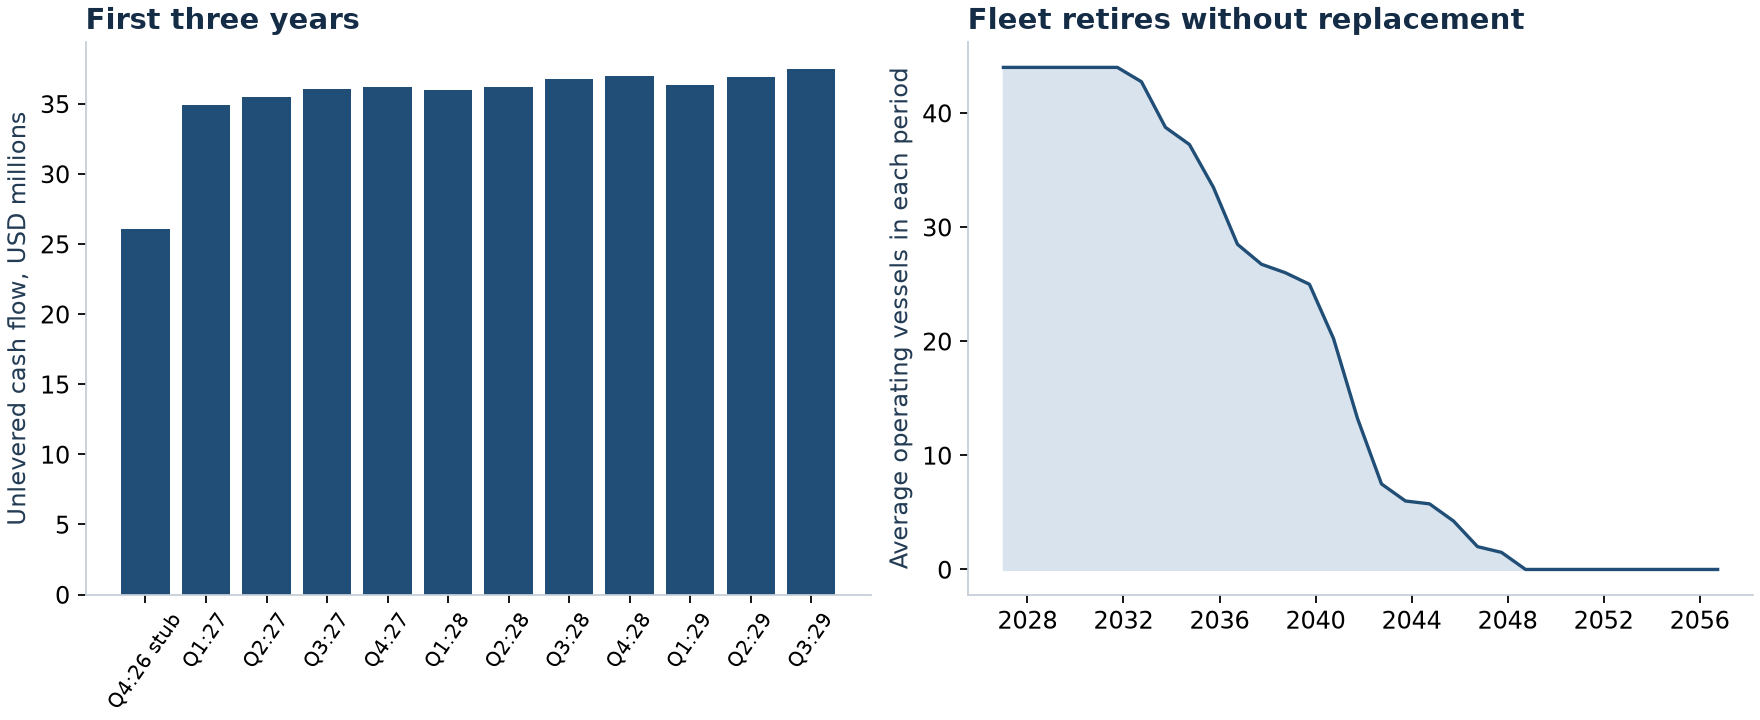

In [5]:
base = cases['base']
display(base.forecast[['label','owned','available','revenue','operating','maintenance','newbuild','scrap','delta_wc','ufcf','pv']].head(12).round(2))
display(base.financing.head(12).round(2))
audit = reconcile(company, OUT / 'excel-calculation-evidence.json')
display({k: v for k, v in audit.items() if k not in ['controls','failures']})
assert audit['status'] == 'pass', audit['failures']
display(Image(filename=str(OUT / 'cash-and-fleet.png')))

## Research limits

The limitations below are part of the model output. Update the reviewed input package as
new filings, fleet transactions, debt balances and independent vessel marks become available.

In [6]:
display(pd.Series(company.metadata['limitations'], name='Limitations'))

0    The $1.42bn June fleet value is inferred from ...
1    Genco Volunteer is added at its disclosed purc...
2    The July–October operating cash bridge is esti...
3    Open-fleet scenarios do not reconstruct every ...
4    The debt facility is modeled as a 2031 bullet;...
5    Drydock cash is normalized from management bud...
6    No replacement fleet is assumed after existing...
Name: Limitations, dtype: object